# Mean-Variance Portfolio Optimization


In [2]:
# hide
%load_ext autoreload
%autoreload 2
%matplotlib inline

import numpy as np
import pandas as pd
from IPython.display import Image, display

A portfolio is the ownership of a set of securities that give rights to a stream of payments. The goal of Markowitz portfolio optimisation is to determine the portfolio holdings that maximise the expected return of the portfolio under a risk constraint. Mathematically, it boils down to maximising a "mean-variance objective". In this section, we review the mathematics of Markowitz portfolio optimisation and how to implement in `python` "mean-variance optimisers" that follow the scikit-learn "fit/predict" API. 

## Markowitz portfolio optimisation

The portfolio universe is made of $N$ assets: 

- $r$ is a vector of returns for each asset (with size $N$); 

- $\alpha$ is the asset return forecast: $\alpha = E(r)$; 

- $V$ is the return covariance matrix that measures that correlation between each asset: $V = Var(r)$; 

- $h$ is a vector of positions/holdings in each of these assets. 

Note: for a vector $v$, we denote $v^T$ as the transpose of $v$. 

A mean-variance objective is an objective that trades off the portfolio expected return (as $h^T \alpha$) against the portfolio expected risk (as $h^T V h$). In practice, it is written as: 

$$U = h^T \alpha - \frac{h^T V h}{2 \lambda},$$

where $\lambda$ is the risk-tolerance.


**Lemma** [mean-variance]: the allocation $h$ that maximizes the mean-variance objective is
$$h = \lambda V^{-1} \alpha. $$

The ex-ante risk is $h^T V h = \lambda^2 \alpha^T V^{-1} \alpha$ and the ex-ante Sharpe ratio is
$$
S = \frac{h^T E(r)}{\sqrt{h^T V h}} = \sqrt{\alpha^T V^{-1} \alpha}. 
$$

**Corollary**: The maximisation of the sharpe ratio is equivalent (up to a scaling factor) the mean-variance optimisation. 

The mean-variance formula is extended to account for the linear constraints
$$A h = b. $$ 

To do so, we introduce the Lagrangian $\mathcal {L}$ (and Lagrange multiplier $\xi$)

$$
\mathcal {L}= h^T \alpha - \frac{h^T V h}{2\lambda} - (h^T A^T - b^T)\xi
$$

The Lagrange multiplier $\xi$ is a `tuning parameter` chosen exactly so that the constraint above holds. At the optimal value of $\xi$, the constrained problem boils down to an unconstrained problem with the adjusted return forecast $\alpha - A^T \xi$.


**Lemma**: the allocation that maximizes the objective $h^T \alpha - \frac{h^T V h}{2 \lambda}$ under the linear constraint $A h = b$ is

$$ h = V^{-1} A^T \left(A V^{-1} A^T \right)^{-1} b + \lambda V^{-1} \left[\alpha - A^T \left(A V^{-1} A^T \right)^{-1} A V^{-1} \alpha \right]$$

*Proof*. With the column‑gradient (numerator‑layout) convention to differentiate with respect to the column vector $\partial h$ (and report gradients as columns), we have: 
$$ \partial (h^T \alpha) = \alpha; \hspace{1cm} \partial (h^T A^T) = A^T; \hspace{1cm} \partial (h^T  V h) = 2 Vh.$$ 
The first-order condition is then: 

$$ \frac{\partial \mathcal {L}}{\partial h} = \alpha - \frac{V h}{\lambda} - A^T \xi =0  \Leftrightarrow  h = \lambda V^{-1}[\alpha - A^T \xi] $$

The parameter $\xi$ is chosen so that $A h = b$

$$b = Ah = \lambda A  V^{-1}[\alpha - A^T \xi]  \Rightarrow  \xi = [A V^{-1}A^T]^{-1} \left[ A  V^{-1}\alpha - \frac{b}{\lambda}  \right]
$$

The holding vector under constraint is

$$ h_{\lambda} = \underbrace {V^{-1} A^T \left(A V^{-1} A^T \right)^{-1} b}_{\text {minimum variance portfolio}} + \underbrace { \lambda V^{-1} \left[\alpha - A^T \left(A V^{-1} A^T \right)^{-1} A V^{-1} \alpha \right]}_{\text {speculative portfolio}} $$

- The first term is what minimises the risk $h^T V h$ under the constraint $Ah =b$ (in particular, it does not depend on expected returns or risk-tolerance).

- The second term is the speculative portfolio (it is sensitive to both inputs).

The efficient frontier is the relation between  expected portfolio return $h^T \alpha$ and portfolio standard deviation $\sqrt{h^T V h}$ for varying level of risk-tolerance
$$ (x, y) \mapsto \left(h_{\lambda}^T \alpha, \sqrt{h_{\lambda}^T V h_{\lambda}} \right)$$

When $b=0$, the efficient frontier between $h_{\lambda}^T \alpha$ and $\sqrt{h_{\lambda}^T V h_{\lambda}}$ is a line through $(0,0)$; otherwise, it is a parabolic curve.

We focus on pure "alpha views" -- that is, long-short "cash-neutral" portfolios where the sum of holdings is zero. In this case $b=0$ and $A = \textbf{1}$ where

$$ \textbf {1} = \left[\begin {array}{ccc} 1  & \ldots & 1  \end {array} \right].$$

## Mean-variance estimators

In the following python file, we introduce:

- `compute_batch_holdings`: computes mean-variance holdings from the constrained formula above
- `MeanVariance`: a multi-asset optimizer following the sklearn `fit`/`predict` API
- `TimingMeanVariance`: a single-asset timing estimator that scales positions by inverse volatility


In [3]:
%%writefile ../skfin/estimators/mean_variance.py
"""Mean-variance portfolio optimization estimators."""

from dataclasses import dataclass, field
from typing import Callable

import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator

from skfin.metrics import sharpe_ratio


def compute_batch_holdings(
    pred: np.ndarray | pd.Series | pd.DataFrame,
    V: np.ndarray,
    A: np.ndarray | None = None,
    risk_target: float | None = None,
) -> np.ndarray:
    """Compute Markowitz portfolio holdings from predictions and covariance.

    Args:
        pred: Return predictions, shape (N,) or (N, K) or (K, N).
        V: Covariance matrix, shape (N, N).
        A: Constraint matrix. None for unconstrained.
        risk_target: Target portfolio volatility. None disables scaling.

    Returns:
        Holdings array, shape (K, N).
    """
    N, _ = V.shape
    if isinstance(pred, (pd.Series, pd.DataFrame)):
        pred = pred.values
    if pred.ndim == 1:
        pred = pred[:, np.newaxis]
    elif pred.shape[1] == N:
        pred = pred.T

    invV = np.linalg.inv(V)
    if A is None:
        M = invV
    else:
        U = invV.dot(A)
        if A.ndim == 1:
            M = invV - np.outer(U, U.T) / U.dot(A)
        else:
            M = invV - U.dot(np.linalg.inv(U.T.dot(A)).dot(U.T))
    h = M.dot(pred)
    if risk_target is not None:
        h = risk_target * h / np.sqrt(np.diag(h.T.dot(V.dot(h))))
    return h.T


@dataclass
class MeanVariance(BaseEstimator):
    """Mean-variance optimizer that computes portfolio holdings from predictions and covariance."""

    transform_V: Callable = field(default=lambda x: np.cov(x.T))
    A: np.ndarray | str | None = "cash-neutral"
    risk_target: float = 1.0

    def __post_init__(self):
        self.holdings_kwargs = {"risk_target": self.risk_target}

    @staticmethod
    def compute_batch_holdings(
        pred: np.ndarray,
        V: np.ndarray,
        A: np.ndarray | None,
        risk_target: float | None,
        **kwargs,
    ) -> np.ndarray:
        """Compute portfolio holdings in batch."""
        return compute_batch_holdings(pred=pred, V=V, A=A, risk_target=risk_target, **kwargs)

    def fit(self, X, y=None):
        self.V_ = self.transform_V(y)
        return self

    def predict(self, X, **kwargs):
        if isinstance(X, (pd.Series, pd.DataFrame)):
            X = X.values
        n_assets = X.shape[1] if X.ndim > 1 else X.shape[0]
        if isinstance(self.A, str) and self.A == "cash-neutral":
            A = np.ones((n_assets, 1))
        else:
            A = self.A
        kwargs = {**kwargs, **self.holdings_kwargs}
        h = self.compute_batch_holdings(pred=X, V=self.V_, A=A, **kwargs)
        return h

    def transform(self, X, **kwargs):
        """Alias for predict (enables sklearn pipeline use)."""
        return self.predict(X, **kwargs)

    def score(self, X, y):
        """Compute Sharpe ratio of the portfolio PnL."""
        return sharpe_ratio(np.sum(X * y, axis=1))


class TimingMeanVariance(BaseEstimator):
    """Single-asset timing estimator that scales positions by inverse volatility."""

    def __init__(
        self,
        transform_V: Callable | None = None,
        a_min: float | None = None,
        a_max: float | None = None,
    ):
        if transform_V is None:
            self.transform_V = lambda x: np.var(x)
        else:
            self.transform_V = transform_V
        self.a_min = a_min
        self.a_max = a_max

    def fit(self, X, y=None):
        self.V_ = self.transform_V(y)
        return self

    def predict(self, X):
        if self.a_min is None and self.a_max is None:
            h = X / self.V_
        else:
            h = np.clip(
                X / np.sqrt(self.V_), a_min=self.a_min, a_max=self.a_max
            ) / np.sqrt(self.V_)
        return h

    def transform(self, X):
        """Alias for predict (enables sklearn pipeline use)."""
        return self.predict(X)


Overwriting ../skfin/estimators/mean_variance.py


## Usage


The implementation maps directly to the constrained formula above:
- `V` is the covariance matrix (estimated from `y` in `fit()`)
- `pred` (or `X` in `predict()`) is the return forecast $\alpha$
- `A` is the constraint matrix (e.g. $\mathbf{1}$ for cash-neutral)
- `risk_target` rescales $h$ so that $\sqrt{h^T V h} = \text{target}$


In [5]:
from skfin.datasets import load_kf_returns
from skfin.estimators.mean_variance import MeanVariance, TimingMeanVariance, compute_batch_holdings
from skfin.plot import bar

returns_data = load_kf_returns(cache_dir="data", force_reload=False)
ret = returns_data["Monthly"]["Average_Value_Weighted_Returns"][:"1999"]
T, N = ret.shape
print(f"{T} months, {N} industries")

882 months, 12 industries


### Cash-neutral constraint


With $A = \mathbf{1}$, the constraint $Ah = 0$ forces the portfolio to be dollar-neutral (long-short).


Sum of holdings (should be ~0): 4.86e-17


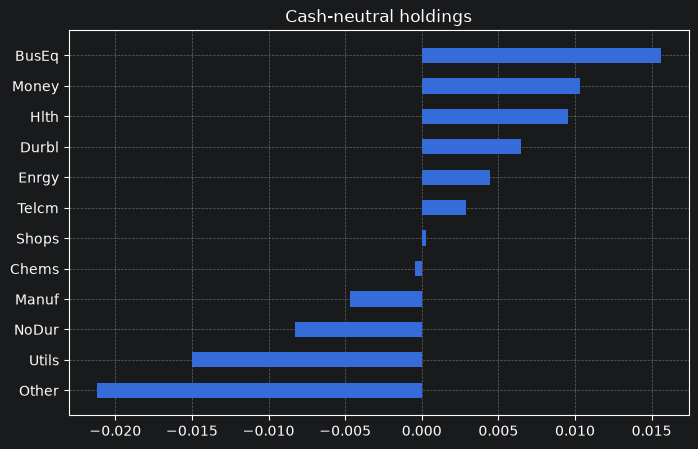

In [6]:
A_ones = np.ones(N)
h_neutral = compute_batch_holdings(ret.mean(), ret.cov(), A_ones)

print(f"Sum of holdings (should be ~0): {h_neutral.sum():.2e}")
bar(pd.Series(h_neutral.squeeze(), index=ret.columns), horizontal=True, title="Cash-neutral holdings")

### Multiple constraints


Stack constraints as columns of $A$. Here: cash-neutral + first asset weight = 0.


In [7]:
A_multi = np.stack([np.ones(N), np.zeros(N)], axis=1)
A_multi[0, 1] = 1  # constrain first asset

h_multi = compute_batch_holdings(pred=ret.mean(), V=ret.cov(), A=A_multi)
print(f"Sum of holdings: {h_multi.sum():.2e}")
print(f"First asset weight: {h_multi.squeeze()[0]:.2e}")

Sum of holdings: 1.35e-16
First asset weight: 3.46e-18


### The `MeanVariance` class


The class wraps `compute_batch_holdings` in the sklearn `fit`/`predict` pattern. `fit()` estimates the covariance from `y`, then `predict()` computes holdings from new return forecasts.


In [8]:
m = MeanVariance(A=np.ones(N), risk_target=None)
m.fit(X=None, y=ret)
h_class = m.predict(ret.mean())

# Verify: class produces same result as calling the function directly
assert np.allclose(h_class, h_neutral)
print("MeanVariance.predict matches compute_batch_holdings: OK")

MeanVariance.predict matches compute_batch_holdings: OK


### Risk targeting


Setting `risk_target=1.0` rescales holdings so that the ex-ante portfolio volatility $\sqrt{h^T V h} = 1$.


In [12]:
m_rt = MeanVariance(A=np.ones(N), risk_target=1.0)
m_rt.fit(X=None, y=ret)
h_risktarget = m_rt.predict(ret.mean()).squeeze()

realized_risk = np.sqrt(h_risktarget @ m_rt.V_ @ h_risktarget)
assert np.isclose(realized_risk, 1.0)
print(f"Ex-ante risk: {realized_risk:.6f} (target: 1.0)")

Ex-ante risk: 1.000000 (target: 1.0)


### Comparing unconstrained vs risk-targeted holdings

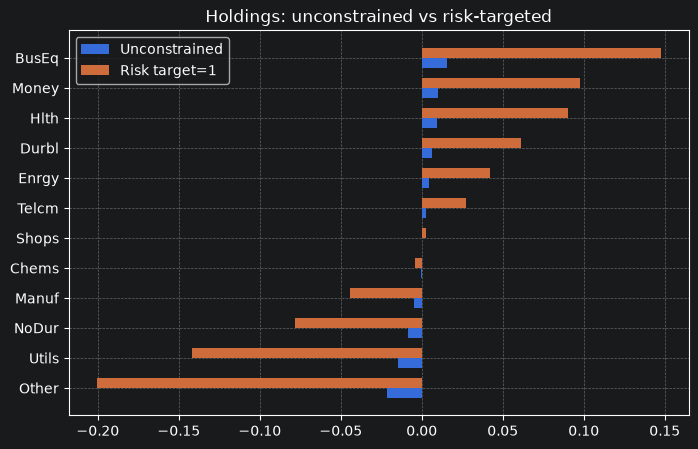

In [13]:
comparison = pd.DataFrame({
    "Unconstrained": h_neutral.squeeze(),
    "Risk target=1": h_risktarget,
}, index=ret.columns)

bar(comparison, horizontal=True, title="Holdings: unconstrained vs risk-targeted")


### Single-asset timing with `TimingMeanVariance`


For a single-asset strategy, `TimingMeanVariance` scales positions by inverse volatility: $h = X / V$. With `a_min`/`a_max`, positions are clipped before scaling — useful to cap leverage.


In [14]:
# Single-asset returns (first industry)
y_single = ret.iloc[:, 0].values
X_signal = np.array([0.01, -0.005, 0.02])  # 3 forecast periods

# Unconstrained timing
tm = TimingMeanVariance()
tm.fit(X=None, y=y_single)
h_timing = tm.predict(X_signal)
print(f"Variance: {tm.V_:.6f}")
print(f"Holdings (unconstrained): {h_timing}")

Variance: 23.446585
Holdings (unconstrained): [ 0.0004265  -0.00021325  0.000853  ]


In [15]:
# With position clipping
tm_clipped = TimingMeanVariance(a_min=-2.0, a_max=2.0)
tm_clipped.fit(X=None, y=y_single)
h_clipped = tm_clipped.predict(X_signal)
print(f"Holdings (clipped): {h_clipped}")
print(f"Max leverage reduced: {abs(h_timing).max():.1f} -> {abs(h_clipped).max():.1f}")

Holdings (clipped): [ 0.0004265  -0.00021325  0.000853  ]
Max leverage reduced: 0.0 -> 0.0


With `a_min`/`a_max` bounds well outside this toy signal's tiny range, the clipping in `TimingMeanVariance` never actually binds here -- its effect only shows up once a signal swings hard enough to demand a leverage cap that would otherwise blow through it.